# Esercizio 1) LS su dati sintetici

## Consegna: 

Considera le 6 coppie di dati $(x_i, y_i)$ che rappresentano 6 città in termini di:
- x : Indice della Qualità della Vita, con valori fra 0 e 100;
- y : Costo Medio di un affitto mensile, con valori non negativi.

| i         | x         | y         |
|-----------|-----------|-----------|
| 1         | 60        | 921.82    |
| 2         | 65        | 947.36    |
| 3         | 70        | 999.86    |
| 4         | 75        | 1050.30   |
| 5         | 80        | 1121.71   |
| 6         | 85        | 1329.49   |



Calcola il modello di regressione (lineare semplice o polinomiale) che meglio descrive i dati forniti.
In particolare:
- visualizza i punti con lo scatterplot;
- fissa il grado del modello lineare e costruisci la matrice di Vandermonde opportuna;
- risolvi la regressione tramite i minimi quadrati implementati da `np.linalg.lstsq`, provando modelli di grado 0, 1, 2 e 3;
- visualizza il polinomio di regressione ottenuto;
- analizza e confronta i residui al variare del grado di approssimazione;
- osserva la *capacità di generalizzazione* dei modelli ottenuti, sull'intero dominio $ x \in [0, 100]$;
- guarda quanto cambiano i risultati (valori di beta ottimali e predizioni) risolvendo il problema dei minimi quadrati con Cholesky (funzione `np.linalg.cholesky`) 
- guarda quanto cambiano i risultati (valori di beta ottimali e predizioni) risolvendo il problema dei minimi quadrati con la SVD e la sua specifica riformulazione con la pseudoinversa di Moore–Penrose.



In [2]:
import numpy as np
import matplotlib.pyplot as plt

#### Lettura dei dati

In [42]:
x = (60,        65,     70,     75,     80,     85)
y = (921.82,    947.36, 999.86, 1050.3, 1121.71, 1329.49)

x = np.array( x )
y = np.array( y )


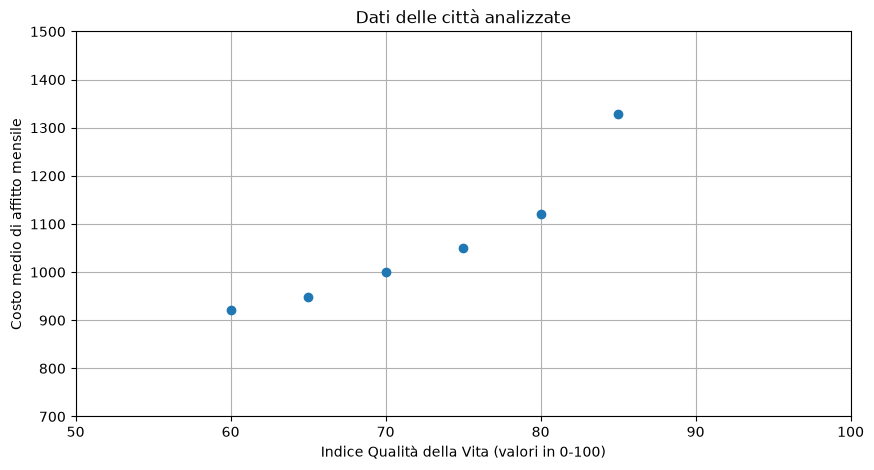

In [31]:
plt.figure(figsize=(10, 5))  
plt.plot(x, y, 'o')
plt.title('Dati delle città analizzate')
plt.xlabel('Indice Qualità della Vita (valori in 0-100)')
plt.ylabel('Costo medio di affitto mensile')
plt.xlim([50, 100])
plt.ylim([700, 1500])
plt.grid()
plt.show()

#### Creazione della matrice e del sistema lineare

In [27]:
# Grado del polinomio
grado = 2

# Matrice del modello
m = len(x)
A = np.zeros((m, grado + 1))

for j in range(grado + 1):
    A[:, j] = x**j

print(A)

[[1.000e+00 6.000e+01 3.600e+03]
 [1.000e+00 6.500e+01 4.225e+03]
 [1.000e+00 7.000e+01 4.900e+03]
 [1.000e+00 7.500e+01 5.625e+03]
 [1.000e+00 8.000e+01 6.400e+03]
 [1.000e+00 8.500e+01 7.225e+03]]


## (A) Risoluzione con np.linalg.lstsq

In [28]:
beta_star, residui, rango, valori_singolari = np.linalg.lstsq(A, y, rcond=None)
print('Soluzione LSQ:', np.round(beta_star, 4))


Soluzione LSQ: [ 3.6333663e+03 -8.7283600e+01  7.0490000e-01]


In [29]:
beta0 = beta_star[0]
beta1 = beta_star[1]
print(f"beta0 = {beta0:.4f}")
print(f"beta1 = {beta1:.4f}")

x_vec = np.linspace(0,100, 200)

if grado==1:
    y_vec = beta0 + beta1*x_vec
else: # grado ==2
    beta2 = beta_star[2]
    print(f"beta2 = {beta2:.4f}")
    y_vec = beta0 + beta1*x_vec + beta2*x_vec**2


beta0 = 3633.3663
beta1 = -87.2836
beta2 = 0.7049


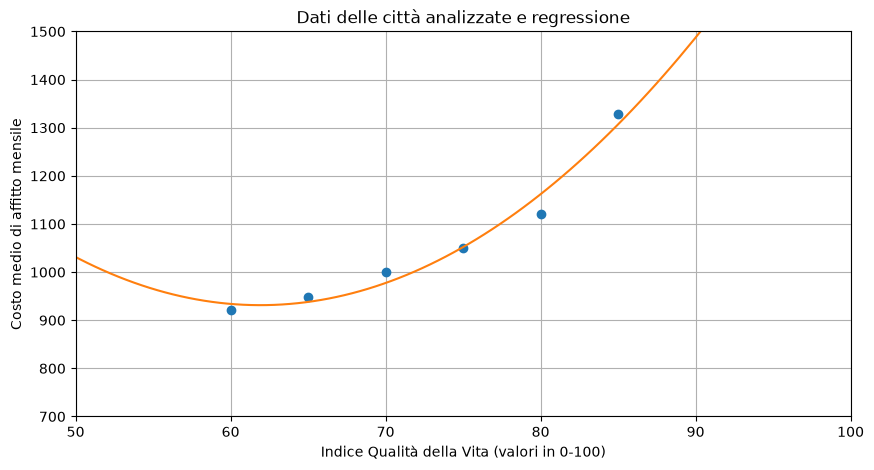

In [32]:
plt.figure(figsize=(10, 5))  
plt.plot(x, y, 'o')
plt.plot(x_vec, y_vec, '-')
plt.title('Dati delle città analizzate e regressione')
plt.xlabel('Indice Qualità della Vita (valori in 0-100)')
plt.ylabel('Costo medio di affitto mensile')
plt.xlim([50, 100])
plt.ylim([700, 1500])
plt.grid()
plt.show()

#### Analisi dei residui

In [50]:
y_star = A @ beta_star
r = y-y_star

print('y stimato:\t', np.round(y_star, 4))
print('y misurato: \t', y)
print('residuo: \t', np.round(r, 4))

y stimato:	 [ 933.9371  938.0726  977.4523 1052.0763 1161.9446 1307.0571]
y misurato: 	 [ 921.82  947.36  999.86 1050.3  1121.71 1329.49]
residuo: 	 [-12.1171   9.2874  22.4077  -1.7763 -40.2346  22.4329]


In [57]:
print('Somma abs(residui): \t', np.sum( np.abs(r) ))
print('Somma (residui)**2:\t', np.dot(r, r))
print('Media abs(residui): \t', np.mean( np.abs(r) ))

Somma abs(residui): 	 108.25600000001702
Somma (residui)**2:	 2860.396148571426
Media abs(residui): 	 18.042666666669504


Verifico se $r$ è un vettore ortogonale a tutte le colonne di $A$, cioè se $A^Tr^*=0$.

In [65]:
prod = A.T @ r

# print(f"{prod[0]:.3e}")   # Funziona se prod[0] è un numero
print('A^T r = ',  np.round(prod, 12))         # np.round(, 12) arrotonda i valori a 12 cifre decimali, ma non impone il formato di stampa
print('||A^T r||_2 =', np.linalg.norm(prod))

A^T r =  [1.739000e-09 1.275320e-07 9.480806e-06]
||A^T r||_2 = 9.48166348129661e-06


#### Generalizzazione del modello sul dominio

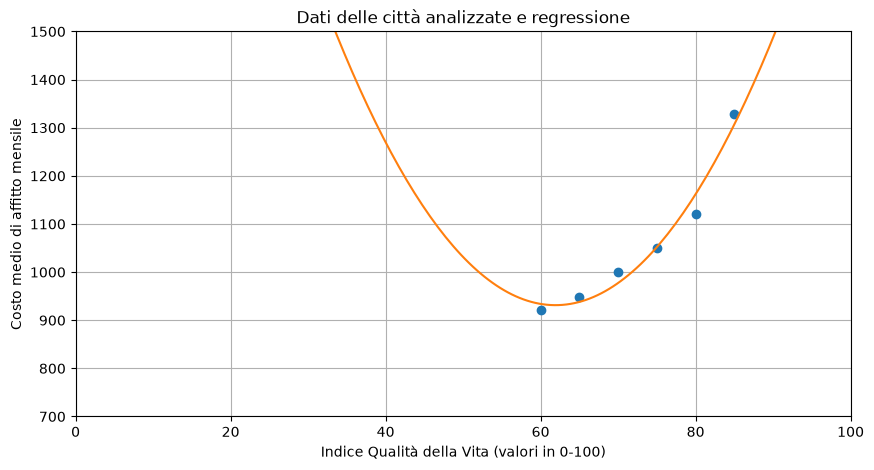

In [52]:
plt.figure(figsize=(10, 5))  
plt.plot(x, y, 'o')
plt.plot(x_vec, y_vec, '-')
plt.title('Dati delle città analizzate e regressione')
plt.xlabel('Indice Qualità della Vita (valori in 0-100)')
plt.ylabel('Costo medio di affitto mensile')
plt.xlim([0, 100])                      # x ha valori in [0, 100]
plt.ylim([700, 1500])
plt.grid()
plt.show()

## (B) Risoluzione con le Eq Normali e Cholesky

In [ ]:
# Risoluzione mediante equazioni normali e Cholesky

G = A.T @ A
c = A.T @ y
L = np.linalg.cholesky(G)

print('A^T A =\n', G)       # matrice simmetrica
print('L =\n', L)           # matrice triangolare inferiore


A^T A =
 [[6.00000000e+00 4.35000000e+02 3.19750000e+04]
 [4.35000000e+02 3.19750000e+04 2.38162500e+06]
 [3.19750000e+04 2.38162500e+06 1.79621875e+08]]
L =
 [[2.44948974e+00 0.00000000e+00 0.00000000e+00]
 [1.77588006e+02 2.09165007e+01 0.00000000e+00]
 [1.30537391e+04 3.03289260e+03 1.52752523e+02]]


In [ ]:
z = np.linalg.solve(L, c)
beta_chol = np.linalg.solve(L.T, z)

print('Soluzione: \t', beta_chol)
print('Confronto con lstsq:\t', np.linalg.norm(beta_chol-beta_star))

Soluzione: 	 [ 3.63336629e+03 -8.72836286e+01  7.04885714e-01]
Confronto con lstsq:	 1.2030775915934463e-08


In [72]:
y_chol = A @ beta_chol
r = y-y_chol

print('y stimato:\t', np.round(y_chol, 4))
print('residuo: \t', np.round(r, 4))
print('Media abs(residui): \t', np.mean( np.abs(r) ))

y stimato:	 [ 933.9371  938.0726  977.4523 1052.0763 1161.9446 1307.0571]
residuo: 	 [-12.1171   9.2874  22.4077  -1.7763 -40.2346  22.4329]
Media abs(residui): 	 18.042666666667987


## (C) Risoluzione con la SVD

In [48]:
# Risoluzione mediante SVD

U, s, VT = np.linalg.svd(A, full_matrices=False)
tol = max(A.shape) * np.finfo(float).eps * s[0]
s_inv = np.array([1/sigma if sigma > tol else 0.0 for sigma in s])
A_piu = VT.T @ np.diag(s_inv) @ U.T
beta_svd = A_piu @ y

print('Valori singolari:', np.round(s, 6))
print('Soluzione SVD:', np.round(beta_svd, 6))
print('||x_SVD-x_lstsq||_2 =', np.linalg.norm(beta_svd-beta_star))

Valori singolari: [1.34034868e+04 1.99254970e+01 2.93040000e-02]
Soluzione SVD: [ 3.63336629e+03 -8.72836290e+01  7.04886000e-01]
||x_SVD-x_lstsq||_2 = 4.548569223362164e-12


In [73]:
y_svd = A @ beta_svd
r = y-y_svd

print('y stimato:\t', np.round(y_svd, 4))
print('residuo: \t', np.round(r, 4))
print('Media abs(residui): \t', np.mean( np.abs(r) ))

y stimato:	 [ 933.9371  938.0726  977.4523 1052.0763 1161.9446 1307.0571]
residuo: 	 [-12.1171   9.2874  22.4077  -1.7763 -40.2346  22.4329]
Media abs(residui): 	 18.042666666670794
